In [29]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [30]:
df=pd.read_csv("/content/archive (1).zip")

In [31]:
df.head

<bound method NDFrame.head of           Model  Year         Region   Color Fuel_Type Transmission  \
0      5 Series  2016           Asia     Red    Petrol       Manual   
1            i8  2013  North America     Red    Hybrid    Automatic   
2      5 Series  2022  North America    Blue    Petrol    Automatic   
3            X3  2024    Middle East    Blue    Petrol    Automatic   
4      7 Series  2020  South America   Black    Diesel       Manual   
...         ...   ...            ...     ...       ...          ...   
49995        i3  2014           Asia     Red    Hybrid       Manual   
49996        i3  2023    Middle East  Silver  Electric       Manual   
49997  5 Series  2010    Middle East     Red    Petrol    Automatic   
49998        i3  2020           Asia   White  Electric    Automatic   
49999        X1  2020  North America    Blue    Diesel       Manual   

       Engine_Size_L  Mileage_KM  Price_USD  Sales_Volume Sales_Classification  
0                3.5      151748      98740          8300                 High  
1                1.6      121671      79219          3428                  Low  
2                4.5       10991     113265          6994                  Low  
3                1.7       27255      60971          4047                  Low  
4                2.1      122131      49898          3080                  Low  
...              ...         ...        ...           ...                  ...  
49995            4.6      151030      42932          8182                 High  
49996            4.2      147396      48714          9816                 High  
49997            4.5      174939      46126          8280                 High  
49998            3.8        3379      58566          9486                 High  
49999            3.3      171003      77492          1764                  Low  

[50000 rows x 11 columns]>

In [32]:
df.tail()

,Model,Year,Region,Color,Fuel_Type,Transmission,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume,Sales_Classification
49995,i3,2014,Asia,Red,Hybrid,Manual,4.6,151030,42932,8182,High
49996,i3,2023,Middle East,Silver,Electric,Manual,4.2,147396,48714,9816,High
49997,5 Series,2010,Middle East,Red,Petrol,Automatic,4.5,174939,46126,8280,High
49998,i3,2020,Asia,White,Electric,Automatic,3.8,3379,58566,9486,High
49999,X1,2020,North America,Blue,Diesel,Manual,3.3,171003,77492,1764,Low


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Model                 50000 non-null  object 
 1   Year                  50000 non-null  int64  
 2   Region                50000 non-null  object 
 3   Color                 50000 non-null  object 
 4   Fuel_Type             50000 non-null  object 
 5   Transmission          50000 non-null  object 
 6   Engine_Size_L         50000 non-null  float64
 7   Mileage_KM            50000 non-null  int64  
 8   Price_USD             50000 non-null  int64  
 9   Sales_Volume          50000 non-null  int64  
 10  Sales_Classification  50000 non-null  object 
dtypes: float64(1), int64(4), object(6)
memory usage: 4.2+ MB


In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.isnull().sum()

,0
Model,0
Year,0
Region,0
Color,0
Fuel_Type,0
Transmission,0
Engine_Size_L,0
Mileage_KM,0
Price_USD,0
Sales_Volume,0


In [36]:
df['Price_USD'] = df['Price_USD'].fillna(df['Price_USD'].mean())
df['Mileage_KM'] = df['Mileage_KM'].fillna(df['Mileage_KM'].mean())
df['Engine_Size_L'] = df['Engine_Size_L'].fillna(df['Engine_Size_L'].mean())
df['Year'] = df['Year'].fillna(df['Year'].median())
df['Sales_Volume'] = df['Sales_Volume'].fillna(df['Sales_Volume'].mean())

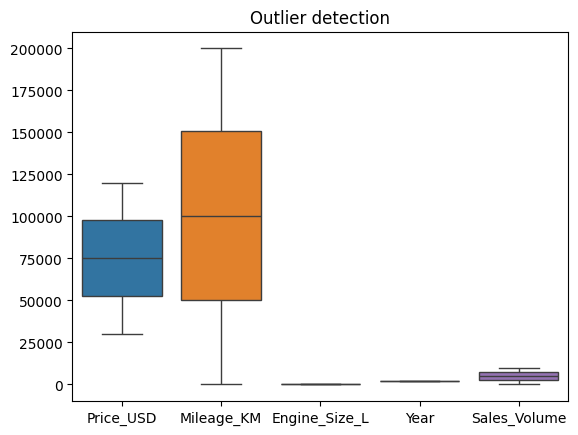

In [37]:
#Outlier Treatment
sns.boxplot(df[['Price_USD','Mileage_KM','Engine_Size_L','Year','Sales_Volume']])
plt.title("Outlier detection")
plt.show()

In [38]:
# Outlier treatment
for col in ['Year','Price_USD', 'Mileage_KM', 'Engine_Size_L','Sales_Volume']:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  df[col] = np.where(df[col] > upper, upper, np.where(df[col] < lower, lower, df[col]))


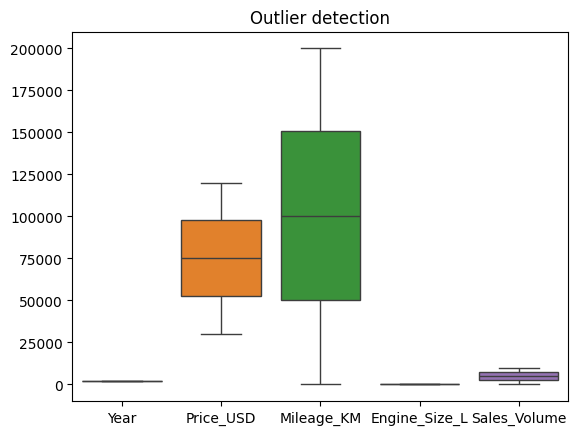

In [39]:
#Outerlier Treatment
sns.boxplot(df[['Year','Price_USD', 'Mileage_KM', 'Engine_Size_L','Sales_Volume']])
plt.title("Outlier detection")
plt.show()

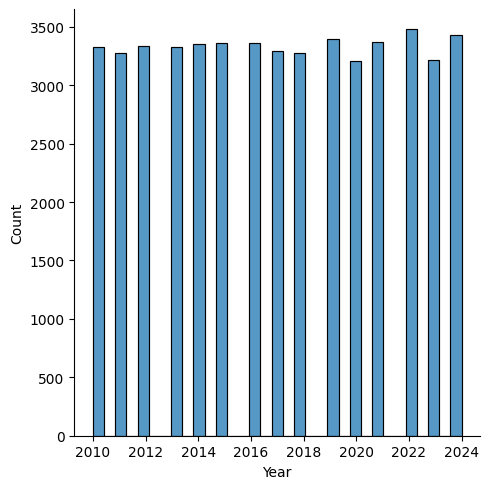

In [40]:
#Univariate Analysis
sns.displot(df['Year'])
plt.show()

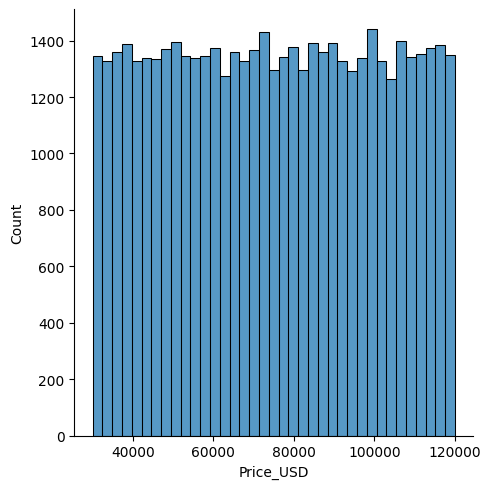

In [41]:
#Univariate Analysis
sns.displot(df['Price_USD'])
plt.show()

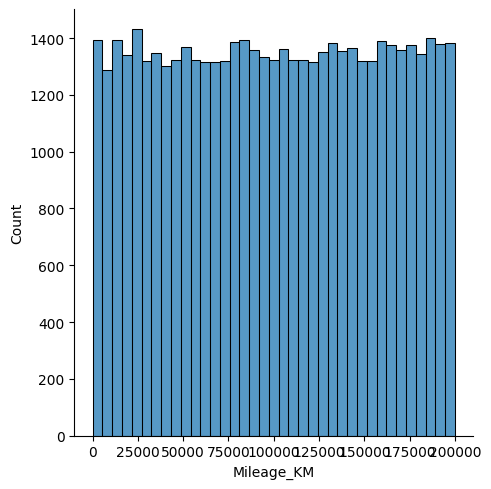

In [42]:
#Univariate Analysis
sns.displot(df['Mileage_KM'])
plt.show()

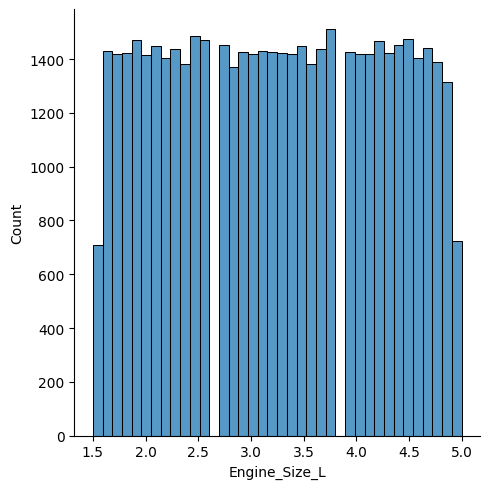

In [43]:
#Univariate Analysis
sns.displot(df['Engine_Size_L'])
plt.show()

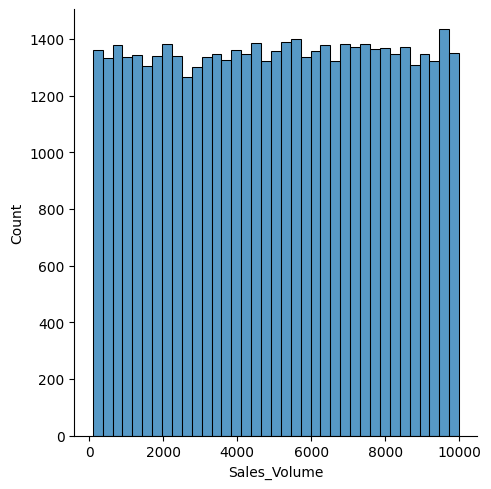

In [44]:
#Univariate Analysis
sns.displot(df['Sales_Volume'])
plt.show()

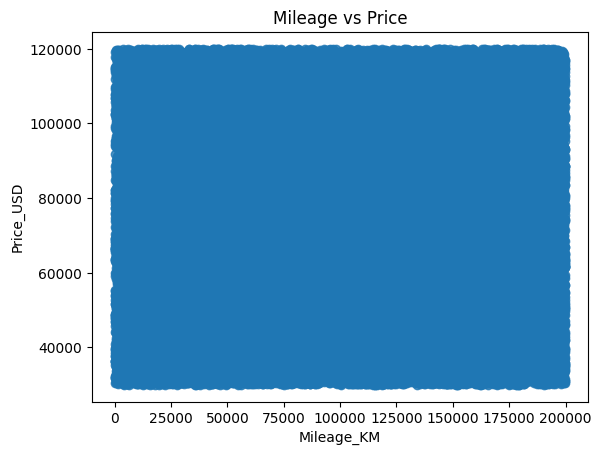

In [45]:
#Bivariate Analysis
#Mileage vs price
sns.regplot(x=df['Mileage_KM'], y=df['Price_USD'])
plt.title('Mileage vs Price')
plt.show()

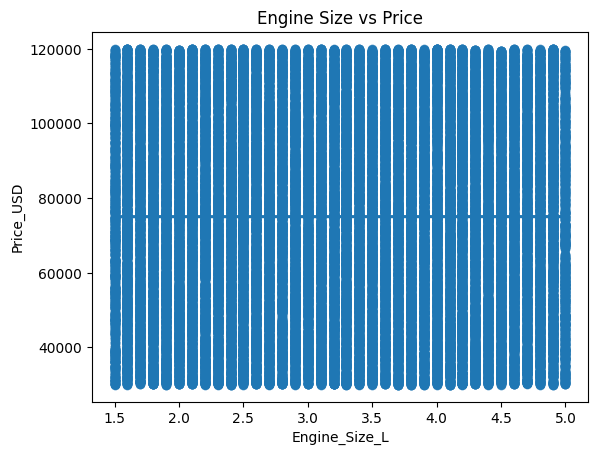

In [46]:
#Bivariate Analysis
# Engine Size vs Price
sns.regplot(x=df['Engine_Size_L'], y=df['Price_USD'])
plt.title('Engine Size vs Price')
plt.show()

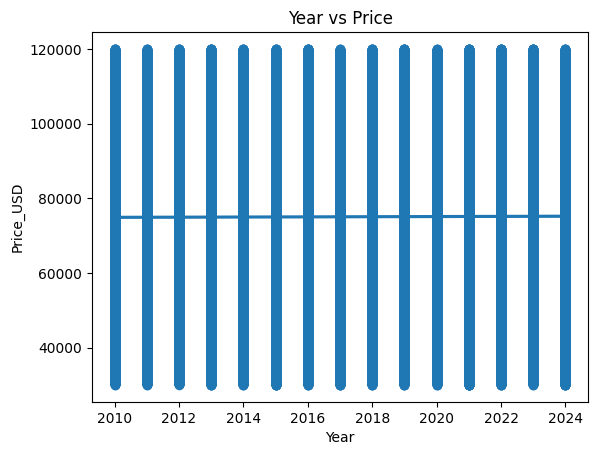

In [47]:
#Bivariate Analysis
# Year vs Price
sns.regplot(x=df['Year'], y=df['Price_USD'])
plt.title('Year vs Price')
plt.show()

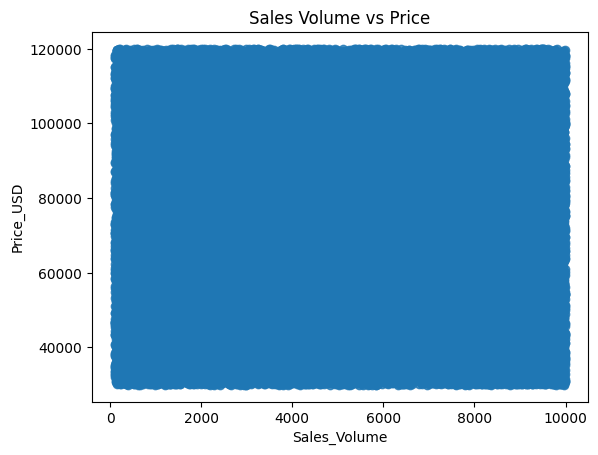

In [48]:
#Bivariate Analysis
# Sales Volume vs Price
sns.regplot(x=df['Sales_Volume'], y=df['Price_USD'])
plt.title('Sales Volume vs Price')
plt.show()

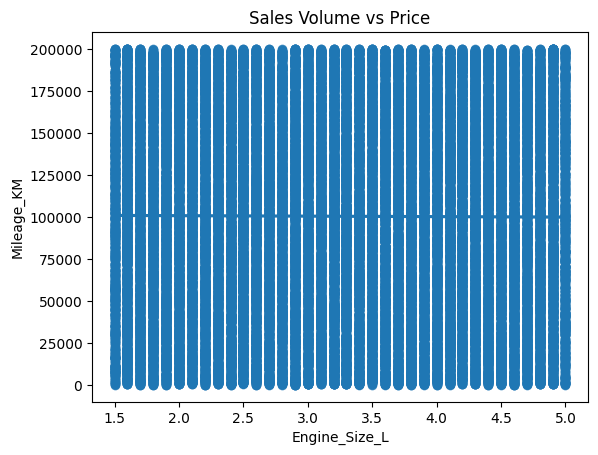

In [49]:
#Bivariate Analysis
# Engine Size vs Mileage
sns.regplot(x=df['Engine_Size_L'], y=df['Mileage_KM'])
plt.title('Sales Volume vs Price')
plt.show()